# 🚀 Модуль 3. Урок 2. Pandas DataFrames: глубокая индексация (.loc, .iloc) и фильтрация без ошибок

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_03_python/lesson_02_pandas_dataframes_indexing.ipynb)

## 📌 Бизнес-контекст и методология
Индексация данных — основа когортного анализа и фильтрации целевых когорт.
Опасная ошибка в продуктовой аналитике — **цепочечное присваивание (Chained Indexing)** вида `df[df['mrr'] > 100]['churn'] = 1`, вызывающее предупреждение `SettingWithCopyWarning`. В результате мутирует не оригинальный DataFrame, а временная копия, и расчеты оттока оказываются ложными.
Всегда используйте эксплицитный доступ через `.loc[строка, колонка]`.

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#e6e6e6'
plt.rcParams['axes.linewidth'] = 0.8

PRIMARY = "#1779ba"
SUCCESS = "#3adb76"
ALERT = "#cc4b37"
WARNING = "#ffae00"
SECONDARY = "#767676"

def ensure_dataset(filename, subfolder=""):
    if os.path.exists(filename):
        return filename
    candidates = [
        os.path.join("course", "datasets", subfolder, filename),
        os.path.join("course", "datasets", filename),
        os.path.join("..", "datasets", subfolder, filename),
        os.path.join("..", "datasets", filename),
        os.path.join("..", "..", "course", "datasets", subfolder, filename),
        os.path.join("datasets", subfolder, filename),
        os.path.join("datasets", filename),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    raw_base = "https://raw.githubusercontent.com/Enlyl/data-analyst-2027/main/course/datasets"
    url = f"{raw_base}/{subfolder}/{filename}" if subfolder else f"{raw_base}/{filename}"
    urllib.request.urlretrieve(url, filename)
    return filename

saas_path = ensure_dataset("saas_users.csv", subfolder="raw")
df_saas = pd.read_csv(saas_path)
print(f"🟢 Датасет saas_users успешно загружен: {df_saas.shape[0]} строк, {df_saas.shape[1]} колонок")

🟢 Датасет saas_users успешно загружен: 2000 строк, 12 колонок


## 🔍 Разбор механики и демонстрация на реальных данных
Сравним синтаксис `.loc` (по меткам и логическим маскам) и `.iloc` (по целочисленным позициям).
Отфильтруем Enterprise-клиентов с высоким риском оттока.

In [2]:
# Демонстрация: Эксплицитная фильтрация через .loc
mask_at_risk = (df_saas['plan'] == 'Enterprise') & (df_saas['is_churned'] == 1)
df_churned_enterprise = df_saas.loc[mask_at_risk, ['user_id', 'company_name', 'industry', 'mrr', 'nps_score']]

print(f"Отток в сегменте Enterprise: {len(df_churned_enterprise)} компаний")
display(df_churned_enterprise.head(5))

Отток в сегменте Enterprise: 9 компаний


,user_id,company_name,industry,mrr,nps_score
121,122,Company_122,Marketing Agency,299.0,9
129,130,Company_130,Fintech,299.0,3
446,447,Company_447,E-commerce,299.0,8
721,722,Company_722,Edtech,299.0,9
850,851,Company_851,Edtech,299.0,7


## 📊 Визуализация бизнес-кейса: Анализ распределения MRR по планам и статусу оттока
Сравним медианный доход и выбросы для активных и ушедших клиентов по тарифным планам с помощью Violin/Boxplot.

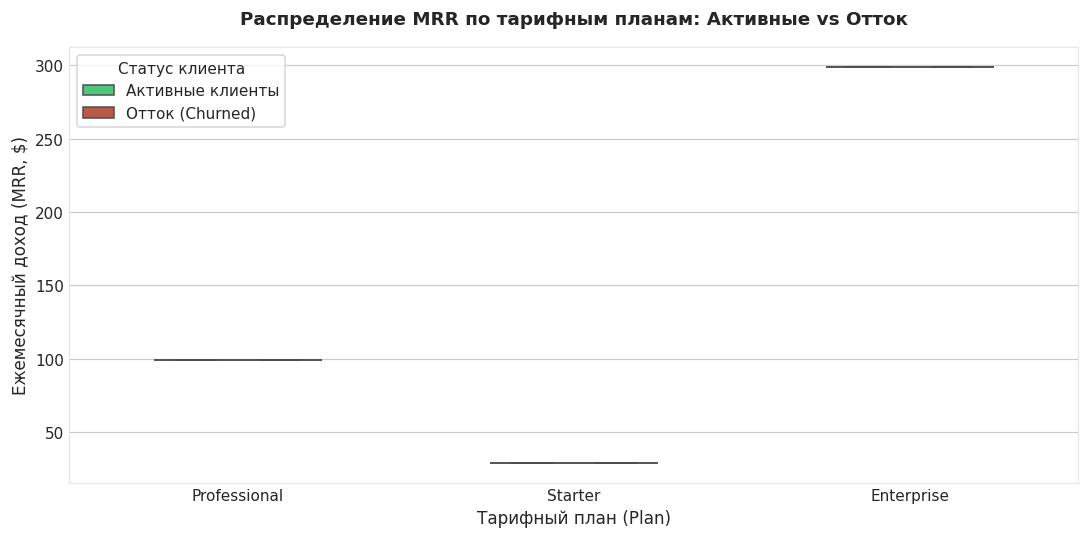

In [3]:
# Построение боксплота с подсветкой групп
fig, ax = plt.subplots(figsize=(10, 5), dpi=110)

palette = {0: SUCCESS, 1: ALERT}
labels = {0: 'Активные клиенты', 1: 'Отток (Churned)'}

df_plot = df_saas.copy()
df_plot['status_label'] = df_plot['is_churned'].map(labels)

sns.boxplot(data=df_plot, x='plan', y='mrr', hue='status_label', 
            palette={'Активные клиенты': SUCCESS, 'Отток (Churned)': ALERT},
            ax=ax, width=0.5, fliersize=3)

ax.set_title("Распределение MRR по тарифным планам: Активные vs Отток", fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel("Тарифный план (Plan)", fontsize=11)
ax.set_ylabel("Ежемесячный доход (MRR, $)", fontsize=11)
ax.legend(title="Статус клиента", frameon=True, facecolor='#ffffff')

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Фильтрация активных клиентов в FinTech
Используя `.loc`, найдите всех активных клиентов (`is_churned == 0`) из индустрии `Fintech` с тарифом `Team` или `Enterprise`. Посчитайте их средний MRR.

In [4]:
### ВАШ КОД ЗДЕСЬ
fintech_mask = (df_saas['is_churned'] == 0) & (df_saas['industry'] == 'Fintech') & (df_saas['plan'].isin(['Team', 'Enterprise']))
df_fintech = df_saas.loc[fintech_mask]
avg_fintech_mrr = df_fintech['mrr'].mean()

print(f"Найдено FinTech клиентов: {len(df_fintech)}")
print(f"Средний MRR в сегменте: ${avg_fintech_mrr:.2f}")

assert not df_fintech.empty, "Клиенты должны быть найдены"
assert (df_fintech['is_churned'] == 0).all(), "Все клиенты должны быть активными"
print("✅ Тест успешно пройден: .loc фильтрация отработала безошибочно!")

Найдено FinTech клиентов: 25
Средний MRR в сегменте: $299.00
✅ Тест успешно пройден: .loc фильтрация отработала безошибочно!


### 💡 Правило безопасности Pandas
Если вам нужно изменить данные в отфильтрованной выборке, всегда создавайте явную независимую копию:
`df_filtered = df.loc[mask, cols].copy()`
Это гарантирует изолированность памяти и предотвращает `SettingWithCopyWarning`.